# Autoencoder image compression

A fully connected autoencoder in PyTorch that compresses 25×50 greyscale images (1,250 pixels) into 32 numbers and reconstructs them, a 39× reduction in the number of values stored.

Year 2 Machine Learning coursework, March 2025. Revisited in October 2026 to make the results reproducible and to compare against a PCA baseline.

## Data

Pixel values are scaled to [0, 1], then the images are split 70/30 into training and test sets.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim

# Fixed seeds so every run gives the same split, weights and results
np.random.seed(42)
torch.manual_seed(42)


images = np.load("dataset_LR.npy")


images = images / 255.0


train_x, test_x = train_test_split(images, test_size=0.3, random_state=42)


train_x = torch.tensor(train_x, dtype=torch.float32)
test_x = torch.tensor(test_x, dtype=torch.float32)

## Model and training

The encoder compresses 1,250 → 512 → 128 → 32 values, and the decoder mirrors it back to 1,250, with ReLU activations and a sigmoid output. It is trained with mean squared error and Adam (learning rate 0.001), batch size 50, for 50 epochs.

In [2]:
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()

       
        self.encoder = nn.Sequential(
            nn.Linear(25 * 50, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 32)
        )

     
        self.decoder = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, 25 * 50),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


autoencoder = Autoencoder()
criterion = nn.MSELoss()
optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)


def train_autoencoder(model, train_x, num_epochs=50, batch_size=50):
    model.train()
    dataset = torch.utils.data.TensorDataset(train_x, train_x)
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

    for epoch in range(num_epochs):
        epoch_loss = 0
        for batch in dataloader:
            inputs, _ = batch
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, inputs)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss / len(dataloader):.6f}")


train_autoencoder(autoencoder, train_x)

Epoch [1/50], Loss: 0.052237
Epoch [2/50], Loss: 0.039413


Epoch [3/50], Loss: 0.029093
Epoch [4/50], Loss: 0.024274


Epoch [5/50], Loss: 0.020658
Epoch [6/50], Loss: 0.019088


Epoch [7/50], Loss: 0.018495
Epoch [8/50], Loss: 0.017503


Epoch [9/50], Loss: 0.015973
Epoch [10/50], Loss: 0.015257


...

Epoch [46/50], Loss: 0.010159


Epoch [47/50], Loss: 0.010031


Epoch [48/50], Loss: 0.009942


Epoch [49/50], Loss: 0.009856


Epoch [50/50], Loss: 0.009741


## Results on the test set

In [3]:
autoencoder.eval()
with torch.no_grad():
    test_reconstructions = autoencoder(test_x)
test_mse = criterion(test_reconstructions, test_x).item()

print(f"Test MSE:  {test_mse:.5f}")
print(f"Test PSNR: {10 * np.log10(1 / test_mse):.1f} dB")

Test MSE:  0.01058
Test PSNR: 19.8 dB


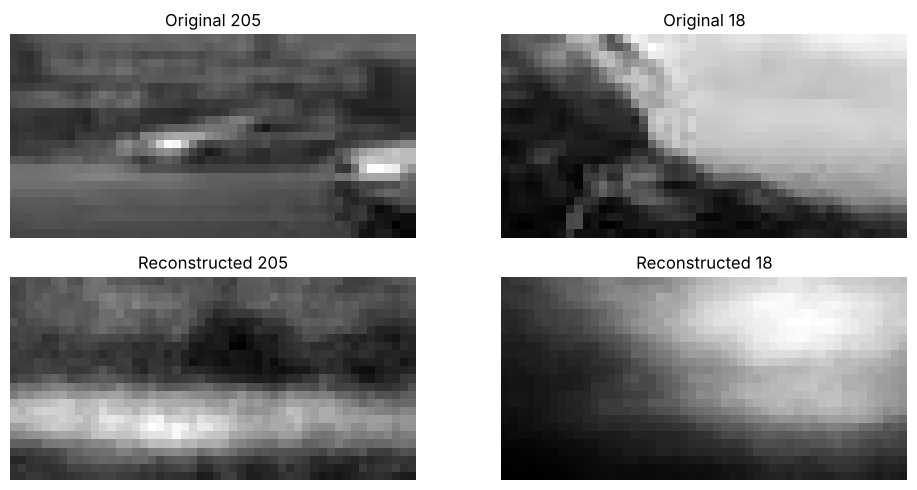

In [4]:
def evaluate_autoencoder(model, test_x, num_images=2):
    model.eval()
    with torch.no_grad():
       
        random_indices = torch.randint(0, test_x.shape[0], (num_images,))
        selected_images = test_x[random_indices]

      
        reconstructions = model(selected_images)

    fig, axes = plt.subplots(2, num_images, figsize=(10, 5))
    for i in range(num_images):
        axes[0, i].imshow(selected_images[i].reshape(25, 50), cmap="gray")
        axes[0, i].axis("off")
        axes[0, i].set_title(f"Original {random_indices[i].item()}")

        axes[1, i].imshow(reconstructions[i].reshape(25, 50), cmap="gray")
        axes[1, i].axis("off")
        axes[1, i].set_title(f"Reconstructed {random_indices[i].item()}")

    plt.tight_layout()
    plt.savefig("reconstructed_images.png", dpi=150)
    plt.show()


evaluate_autoencoder(autoencoder, test_x)

## Comparison with PCA

PCA with 32 components is a natural baseline: it compresses each image to the same 32 numbers, but uses only a linear projection.

In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=32).fit(train_x.numpy())
pca_reconstructions = pca.inverse_transform(pca.transform(test_x.numpy()))
pca_mse = np.mean((pca_reconstructions - test_x.numpy()) ** 2)

print(f"{'Method (32 numbers per image)':<32}{'Test MSE':>10}{'PSNR':>10}")
for name, mse in [("Autoencoder (this model)", test_mse), ("PCA, 32 components", pca_mse)]:
    print(f"{name:<32}{mse:>10.5f}{10 * np.log10(1 / mse):>8.1f} dB")

Method (32 numbers per image)     Test MSE      PSNR
Autoencoder (this model)           0.01058    19.8 dB
PCA, 32 components                 0.00500    23.0 dB


PCA reconstructs the test images with lower error than the autoencoder at the same compression. With only 840 training images, the fully connected network has about 1.4 million parameters to fit and doesn't learn a better code than the linear projection. Convolutional layers, which share weights across the image and exploit local structure, would be the natural next step towards beating the PCA baseline.